# Advanced tutorial: topology, passive outlets, and your own data

This notebook reads the accepted 31-day, three-reservoir snapshot. It does not
run a new network simulation. The example demonstrates parallel tributary
topology, isolated reservoir state, a physical passive outlet, and the settings
that must change for another catchment.

![Accepted three-reservoir month](../examples/fe_walter/reference_outputs/multi_reservoir_month/figures/overview.png)

## Setup

All tables and plots come from `examples/fe_walter/reference_outputs/multi_reservoir_month/baseline`
and its accepted causality comparison.

In [1]:
from pathlib import Path
import html, json, re, sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/hydrocnhs").is_dir())
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from llm_reservoir_agent.workflow import load_settings
from llm_reservoir_agent.verification import verify_run
from tutorials.inspect_decision_flow import load_decision_flow

class ReadableText:
    """Render preserved text as a readable notebook block."""
    def __init__(self, title, text):
        self.title, self.text = title, text
    def _repr_markdown_(self):
        fence = "`" * max(4, 1 + max((len(run) for run in re.findall(r"`+", self.text)), default=0))
        return f"#### {self.title}\n\n{fence}text\n{self.text}\n{fence}"
    def _repr_html_(self):
        return f'<h4>{html.escape(self.title)}</h4><pre class="prompt-text">{html.escape(self.text)}</pre>'

def jsonl(path):
    return [json.loads(line) for line in Path(path).read_text(encoding="utf-8").splitlines()]

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.figsize": (9, 4.8), "axes.grid": True, "figure.dpi": 120})

## 1. Read the saved topology

FE Walter and Beltzville contribute to the Lehigh branch; Prompton contributes
to the Lackawaxen branch. These are parallel tributaries, not a three-dam
cascade. The managed outlet is the sum of these contributions, not full river
discharge.

In [2]:
month = ROOT / "examples/fe_walter/reference_outputs/multi_reservoir_month"
baseline = month / "baseline"
experiment = json.loads((baseline / "experiment.json").read_text(encoding="utf-8"))
network = experiment["network"]
reservoir_rows = []
for name, settings in network["reservoirs"].items():
    physical = settings["physical"]
    reservoir_rows.append({
        "reservoir": name,
        "mode": settings["operation_mode"],
        "initial storage (m³)": physical["initial_storage_m3"],
        "minimum release (m³/s)": physical["minimum_release_cms"],
        "maximum release (m³/s)": physical["maximum_release_cms"],
    })
connections = pd.DataFrame([{
    "source": edge["source"], "target": edge["target"],
    "unit hydrograph": str(edge["unit_hydrograph"]),
} for edge in network["connections"]])
display(pd.DataFrame(reservoir_rows))
display(connections)

,reservoir,mode,initial storage (m³),minimum release (m³/s),maximum release (m³/s)
0,FEWalter,controlled,2.764865e+06,1.415842,283.168466
1,Beltzville,controlled,5.319448e+07,0.000000,28.316847
2,Prompton,passive_outlet,4.698743e+06,0.000000,99.108963


,source,target,unit hydrograph
0,FEWalter,LehighContribution,[1.0]
1,Beltzville,LehighContribution,[1.0]
2,Prompton,LackawaxenContribution,[1.0]
3,LehighContribution,ManagedContributionOutlet,[1.0]
4,LackawaxenContribution,ManagedContributionOutlet,[1.0]


## 2. Passive outlet and state isolation

Prompton has no LLM agent. Its saved discharge is computed from a provisional
storage–discharge curve and daily water balance. The two pulse experiments show
that changing one controlled reservoir changes its own subsequent storage and
downstream contribution while sibling natural inflow and physical transitions
remain byte-for-byte equivalent.

In [3]:
summary = json.loads((baseline / "summary.json").read_text(encoding="utf-8"))["summary"]
comparison = json.loads((month / "comparison.json").read_text(encoding="utf-8"))
passive = network["reservoirs"]["Prompton"]["passive_outlet"]
status = pd.DataFrame([{
    "days": summary["days"],
    "reservoirs": summary["reservoir_count"],
    "reservoir-days": sum(summary["completed_reservoir_days"].values()),
    "model calls": summary["observed_network_calls"],
    "audit counts": str(summary["audit_counts"]),
    "operating strategy accepted": summary["operating_strategy_accepted"],
    "passive rating validated": passive["provenance"]["operationally_validated"],
}])
pulses = pd.DataFrame([{
    "scenario": name,
    "reservoir": values["reservoir"],
    "date": values["date"],
    "release increment (m³/s)": values["requested_increment_cms"],
    "final own-storage decrease (m³)": values["final_storage_decrease_m3"],
    "siblings unchanged": values["sibling_natural_inflow_and_physical_transitions_equal"],
} for name, values in comparison["scenarios"].items()])
display(status)
display(pulses)

,days,reservoirs,reservoir-days,model calls,audit counts,operating strategy accepted,passive rating validated
0,31,3,93,0,{'UNKNOWN': 93},None,False


,scenario,reservoir,date,release increment (m³/s),final own-storage decrease (m³),siblings unchanged
0,fe_pulse,FEWalter,2016-01-04,5.0,432000.0,True
1,belt_pulse,Beltzville,2016-01-15,2.0,172800.0,True


,date,reservoir_id,inflow (m³/s),outflow (m³/s),end storage (m³)
0,2016-01-01,fe_walter,32.125319,32.125319,2.764865e+06
1,2016-01-02,fe_walter,22.353047,22.353047,2.764865e+06
2,2016-01-03,fe_walter,14.193931,14.193931,2.764865e+06
3,2016-01-04,fe_walter,9.687468,9.687468,2.764865e+06
4,2016-01-05,fe_walter,7.383696,7.383696,2.764865e+06
5,2016-01-06,fe_walter,6.227053,6.227053,2.764865e+06
6,2016-01-07,fe_walter,5.642252,5.642252,2.764865e+06
7,2016-01-08,fe_walter,5.337562,5.337562,2.764865e+06
8,2016-01-09,fe_walter,5.169019,5.169019,2.764865e+06


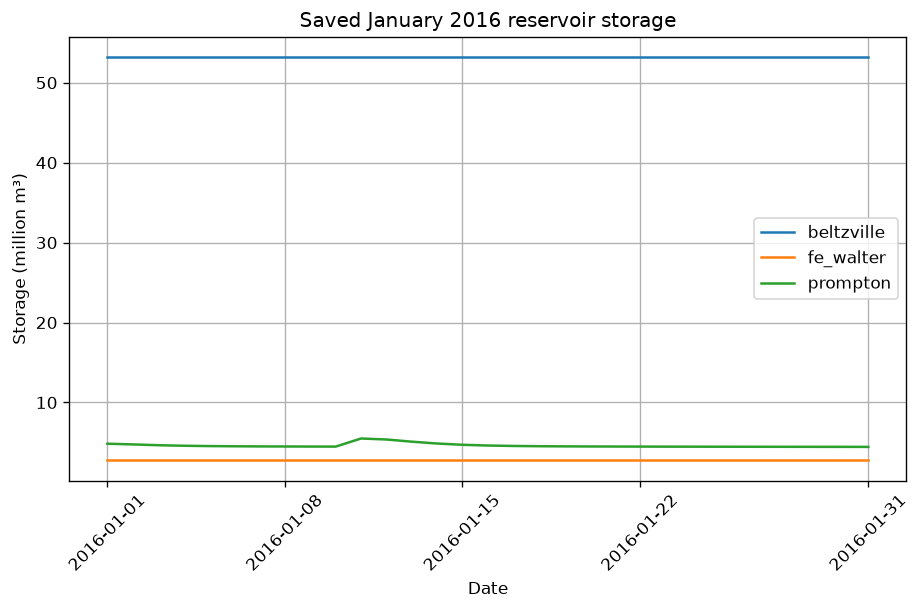

In [4]:
trajectory = pd.read_csv(baseline / "reservoir_trajectory.csv")
trajectory["date"] = trajectory["date"].str[:10]
display(trajectory[["date", "reservoir_id", "inflow_cms", "total_outflow_cms", "storage_end_m3"]].head(9).rename(columns={
    "inflow_cms": "inflow (m³/s)", "total_outflow_cms": "outflow (m³/s)",
    "storage_end_m3": "end storage (m³)"}))
fig, ax = plt.subplots()
for reservoir, group in trajectory.groupby("reservoir_id"):
    ax.plot(group["date"], group["storage_end_m3"] / 1e6, label=reservoir)
ax.set(title="Saved January 2016 reservoir storage", ylabel="Storage (million m³)", xlabel="Date")
ax.legend()
dates = trajectory["date"].drop_duplicates().tolist()
ax.set_xticks([dates[index] for index in (0, 7, 14, 21, 30)])
ax.tick_params(axis="x", rotation=45)
export = ROOT / "tutorials/assets/three_reservoir_month.png"
export.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(export, dpi=160, bbox_inches="tight", metadata={"Software": "HydroOpsLM tutorial"})
display(fig)

## 3. Routing and audit limits

The accepted snapshot independently verifies native routing and mass balance,
but `UH=[1]` remains uncalibrated. All 93 strategy audits are `UNKNOWN` because
this fixture has no operating-policy auditor. File and physics acceptance do
not establish strategy quality or live readiness.

In [5]:
checks = pd.DataFrame([
    ("max system residual", summary["max_system_balance_residual_m3"], "m³"),
    ("final channel storage", summary["final_channel_storage_m3"], "m³"),
    ("natural inputs changed", comparison["natural_hydrologic_inputs_changed"], "boolean"),
    ("routing calibrated", comparison["routing_calibrated"], "boolean"),
    ("outlet is full river", comparison["outlet_represents_full_river"], "boolean"),
    ("delayed reservoir transitions unchanged", comparison["delay"]["reservoir_transitions_unchanged"], "boolean"),
    ("delayed final in-transit storage", comparison["delay"]["final_in_transit_storage_m3"], "m³"),
], columns=["check", "value", "unit"])
display(checks)

,check,value,unit
0,max system residual,0.0,m³
1,final channel storage,0.0,m³
2,natural inputs changed,False,boolean
3,routing calibrated,False,boolean
4,outlet is full river,False,boolean
5,delayed reservoir transitions unchanged,True,boolean
6,delayed final in-transit storage,891255.261177,m³


## 4. Bring your own catchment

Use the generic YAML/module manual for syntax and the native HydroCNHS workflow
for forcing, routing, calibration, and validation. Do not copy FE Walter facts,
capacities, prompts, knowledge, targets, or auditors into another reservoir.

In [6]:
own_data = pd.DataFrame([
    ("Hydrology", "Own forcing, basin geometry, parameters, C&V period", "Native HydroCNHS setup"),
    ("Network", "Reservoir nodes, junctions, local inflow applied once, calibrated UH", "Case JSON"),
    ("Physics", "Storage limits, initial state, outlets, losses, units", "Reservoir physical profile"),
    ("Decision", "Own prompt, knowledge, schema, model budget", "Experiment YAML / modules"),
    ("Audit", "Versioned reservoir-specific operating rules", "Auditor configuration"),
    ("Readiness", "Offline fixtures, conservation, routing, provenance, explicit live approval", "Verification evidence"),
], columns=["layer", "replace with site-specific evidence", "where to configure"])
display(own_data)

,layer,replace with site-specific evidence,where to configure
0,Hydrology,"Own forcing, basin geometry, parameters, C&V period",Native HydroCNHS setup
1,Network,"Reservoir nodes, junctions, local inflow applied once, calibrated UH",Case JSON
2,Physics,"Storage limits, initial state, outlets, losses, units",Reservoir physical profile
3,Decision,"Own prompt, knowledge, schema, model budget",Experiment YAML / modules
4,Audit,Versioned reservoir-specific operating rules,Auditor configuration
5,Readiness,"Offline fixtures, conservation, routing, provenance, explicit live approval",Verification evidence


[Generic YAML settings](../docs/USER_GUIDE.md) ·
[Module interfaces](../docs/LLM_MODULES.md) ·
[Native HydroCNHS hydrology and C&V](../docs/HYDROLOGY_SETUP.md) ·
[Accepted three-reservoir evidence](../examples/fe_walter/reference_outputs/multi_reservoir_month/README.md)